In [ ]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.lines import Line2D 
from matplotlib import gridspec
import matplotlib.colors as colors
import matplotlib.cm as cm
import matplotlib.colors as mcolors
from matplotlib import cm
from matplotlib.patches import Patch

import os
import scanpy as sc

import seaborn as sns
import snapatac2 as snap

snap.__version__



plt.rcParams['figure.dpi'] = 300
plt.rcParams['font.size'] = 14
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = [font for font in 'Liberation Sans, DejaVu Sans, Arial, Helvetica, Lucida Grande, Verdana, Geneva, Lucid, Avant Garde, sans-serif'.split(', ')] 
plt.rcParams['mathtext.fontset'] = 'stixsans'

plt.rcParams['axes.linewidth'] = 1
plt.rcParams['grid.linewidth'] = 1
plt.rcParams['lines.linewidth'] = 2
plt.rcParams['lines.markersize'] = 6

/home/syyang/python_virtuenv/atac_tobias3.13/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
cat_colors_list = [ '#263238','#2E5BFF', "#D4AF37", '#D81B60', '#558B2F', '#7B1FA2', '#E65100']  # ,   '#94A3B8' 
unique_categories = ['common',  'SADE unique', 'CR unique', 'TSS unique',  'SADE+CR, not TSS', 'SADE+TSS, not CR', 'CR+TSS, not SADE', ]
cat_colors_map = dict(zip(unique_categories, cat_colors_list))    


jitter_width = 0.25
position_offset = [0] + [-jitter_width] * 3 + [jitter_width] * 3  # Adjust offsets for each category
cat_position_map = dict(zip(unique_categories, position_offset))


scanpy_colors = [    
    '#1f77b4',
    '#ff7f0e', 
    '#2ca02c',
    '#d62728', 
    '#9467bd', 
    '#8c564b', 
    '#e377c2', 
    '#bcbd22', 
    '#17becf', 
    '#c7c7c7', 
    '#ffbb78',
    '#98df8a']
scanpy_cluster = ['0', '1', '2', '3', '4', '5', '6', '7', '8', '9', '10', '11']
scanpy_color_map = dict(zip(scanpy_cluster, scanpy_colors))

In [3]:
def add_jittered_points(ax, data_group, position, jitter_width=0.3, s = 15, alpha=0.5, color='orange', marker='*', edgecolors='none', lw=1):
    x_jittered = position + np.random.uniform(-jitter_width, jitter_width, size=len(data_group))
    ax.scatter(x_jittered, data_group, color=color, alpha=alpha, s=s, zorder=1, marker=marker, lw=lw, edgecolors=edgecolors) # s controls point size


In [4]:
SADEvsCR_unique_categoris = ['both', 'entropy_only', 'cr_only', 'none', 'tss_only']
SADEcsCR_labels = ['Overlap', 'SADE unique', 'CR unique', 'Neither', 'TSSe unique']
SADEvsCR_colors = ['#0C5B28', '#2E5BFF', '#F59E0B', '#94A3B8', '#D81B60']

SADEvsCR_colors_map = dict(zip(SADEvsCR_unique_categoris, SADEvsCR_colors))
SADEvsCR_label_map = dict(zip(SADEvsCR_unique_categoris, SADEcsCR_labels))

jitter_width = 0.25
SADEvsCR_position_offset = [0] + [-jitter_width] * 2 + [jitter_width] * 2  # Adjust offsets for each category
SADEvsCR_cat_position_map = dict(zip(SADEvsCR_unique_categoris, SADEvsCR_position_offset))

## Load Data

In [27]:
entropy_dir = '/mnt/hdd_bob/syy/adipose/atac/res/VIB_10xmultiome_2_WS3000F'
Union_cell_subdir = os.path.join(entropy_dir, '_cell_calling_comparison')

Union_cell_rna_cluster_file = os.path.join(Union_cell_subdir,  'Union_cell_3set_with_RNA_cluster.tsv')
Union_cell_rna_cluster_df = pd.read_csv(Union_cell_rna_cluster_file, sep='\t', index_col=0)
Union_cell_rna_cluster_df['atac_barcode'] = Union_cell_rna_cluster_df.index.map(lambda x: x + '-1') 

union_cell_noDebrisDoublet_cluster_file = os.path.join(Union_cell_subdir, '_SNAPataC_analysis', 'snap_cluster_unioncells_noDebrisDoublets.tsv')

union_cell_noDebrisDoublet_cluster_df = pd.read_csv(union_cell_noDebrisDoublet_cluster_file, sep='\t', index_col=0)

data = sc.read_h5ad(os.path.join(Union_cell_subdir, '_SNAPataC_analysis', 'binnedGenome_all_unioncells.h5ad'))

data.obs['leiden_RNA_scVI'] = data.obs.index.map(Union_cell_rna_cluster_df['leiden_RNA_scVI']).fillna('no_rna_info')
data.obs['filtered_leiden'] = data.obs.index.map(union_cell_noDebrisDoublet_cluster_df['filtered_leiden']).fillna('Debris_or_doublet')

data.obs['debris_doublets_flag'] = data.obs.apply(lambda row: 
    'debrisNdoublet' if row['DNA_debris'] == 'YES' and row['amulet_doublet_atac'] == True \
        else ('doublets' if row['amulet_doublet_atac'] == True \
            else ('Debris' if row['DNA_debris'] == 'YES' else 'clean')), axis=1)


In [28]:
data

AnnData object with n_obs × n_vars = 2384 × 6062095
    obs: 'n_fragment', 'frac_dup', 'frac_mito', 'rna_pass_CR', 'atac_pass_CR', 'atac_pass_entropy', 'atac_pass_archr_TSS', '_2set_identified_by_atac_SC', '_2set_identified_by_atac_ST', '_3set_identified_by_atac', 'DNA_debris', 'amulet_doublet_atac', 'tsse', 'leiden', 'leiden_RNA_scVI', 'filtered_leiden', 'debris_doublets_flag'
    var: 'count', 'selected'
    uns: 'DNA_debris_colors', 'TSS_profile', '_3set_identified_by_atac_colors', 'amulet_doublet_atac_colors', 'frac_overlap_TSS', 'leiden_colors', 'library_tsse', 'reference_sequences', 'rna_pass_CR_colors', 'spectral_eigenvalue'
    obsm: 'X_spectral', 'X_umap', 'fragment_paired'
    obsp: 'distances'

In [29]:
data.obs.head(2)

,n_fragment,frac_dup,frac_mito,rna_pass_CR,atac_pass_CR,atac_pass_entropy,atac_pass_archr_TSS,_2set_identified_by_atac_SC,_2set_identified_by_atac_ST,_3set_identified_by_atac,DNA_debris,amulet_doublet_atac,tsse,leiden,leiden_RNA_scVI,filtered_leiden,debris_doublets_flag
AAACAAGCAAGTTAGT-1,2412,0.592705,0.0,True,True,True,True,both,both,common,NO,False,37.408568,7,3,9.0,clean
AAACAAGCATTTCTTC-1,9027,0.590816,0.0,True,True,True,True,both,both,common,NO,False,11.363636,0,0,0.0,clean


In [30]:
data.obs['filtered_leiden'].value_counts()

filtered_leiden
0.0                  292
1.0                  240
2.0                  225
3.0                  205
4.0                  197
5.0                  190
7.0                  178
6.0                  178
8.0                  157
9.0                  148
10.0                 140
11.0                 136
Debris_or_doublet     98
Name: count, dtype: int64

In [31]:
data.obs[(data.obs['debris_doublets_flag']== 'clean') & (data.obs['filtered_leiden']!= '0.0')].groupby(['rna_pass_CR'], dropna=False).size()

rna_pass_CR
False     330
True     1956
dtype: int64

In [32]:
data.obs.groupby(['rna_pass_CR', 'debris_doublets_flag', 'filtered_leiden']).size().unstack(fill_value=0)

filtered_leiden                   0.0  1.0  2.0  3.0  4.0  5.0  6.0  7.0  8.0  \
rna_pass_CR debris_doublets_flag                                                
False       Debris                  0    0    0    0    0    0    0    0    0   
            clean                 285    1    5   12    8    0    7    1    1   
            debrisNdoublet          0    0    0    0    0    0    0    0    0   
            doublets                0    0    0    0    0    0    0    0    0   
True        clean                   7  239  220  193  189  190  171  177  156   
            debrisNdoublet          0    0    0    0    0    0    0    0    0   
            doublets                0    0    0    0    0    0    0    0    0   

filtered_leiden                   9.0  10.0  11.0  Debris_or_doublet  
rna_pass_CR debris_doublets_flag                                      
False       Debris                  0     0     0                  2  
            clean                   7     2     1                  0  
            debrisNdoublet          0     0     0                  6  
            doublets                0     0     0                  2  
True        clean                 141   138   135                  0  
            debrisNdoublet          0     0     0                 14  
            doublets                0     0     0                 74

In [33]:
data.obs.groupby(['rna_pass_CR']).size()

rna_pass_CR
False     340
True     2044
dtype: int64

In [34]:
data.obs[(data.obs['amulet_doublet_atac'] == True) | (data.obs['DNA_debris'] == 'YES') ].groupby(['_3set_identified_by_atac']).size()

/tmp/ipykernel_7760/2208233013.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  data.obs[(data.obs['amulet_doublet_atac'] == True) | (data.obs['DNA_debris'] == 'YES') ].groupby(['_3set_identified_by_atac']).size()


_3set_identified_by_atac
CR unique           22
CR+TSS, not SADE     0
SADE unique          0
SADE+CR, not TSS    11
SADE+TSS, not CR     0
TSS unique           0
common              65
dtype: int64

In [36]:
# data.obs['debris_doublets_flag_mod'] = data.obs['debris_doublets_flag'].replace({'debrisNdoublet': 'debris,doublet', 'doublets': 'debris,doublet', 'Debris': 'debris,doublet'})
data.obs['_2set_identified_by_atac_SC_mod'] = data.obs['_2set_identified_by_atac_SC'].replace('none', 'tss_only')

/tmp/ipykernel_7760/1323122304.py:2: FutureWarning: The behavior of Series.replace (and DataFrame.replace) with CategoricalDtype is deprecated. In a future version, replace will only be used for cases that preserve the categories. To change the categories, use ser.cat.rename_categories instead.
  data.obs['_2set_identified_by_atac_SC_mod'] = data.obs['_2set_identified_by_atac_SC'].replace('none', 'tss_only')


# Vis

# TSSe 

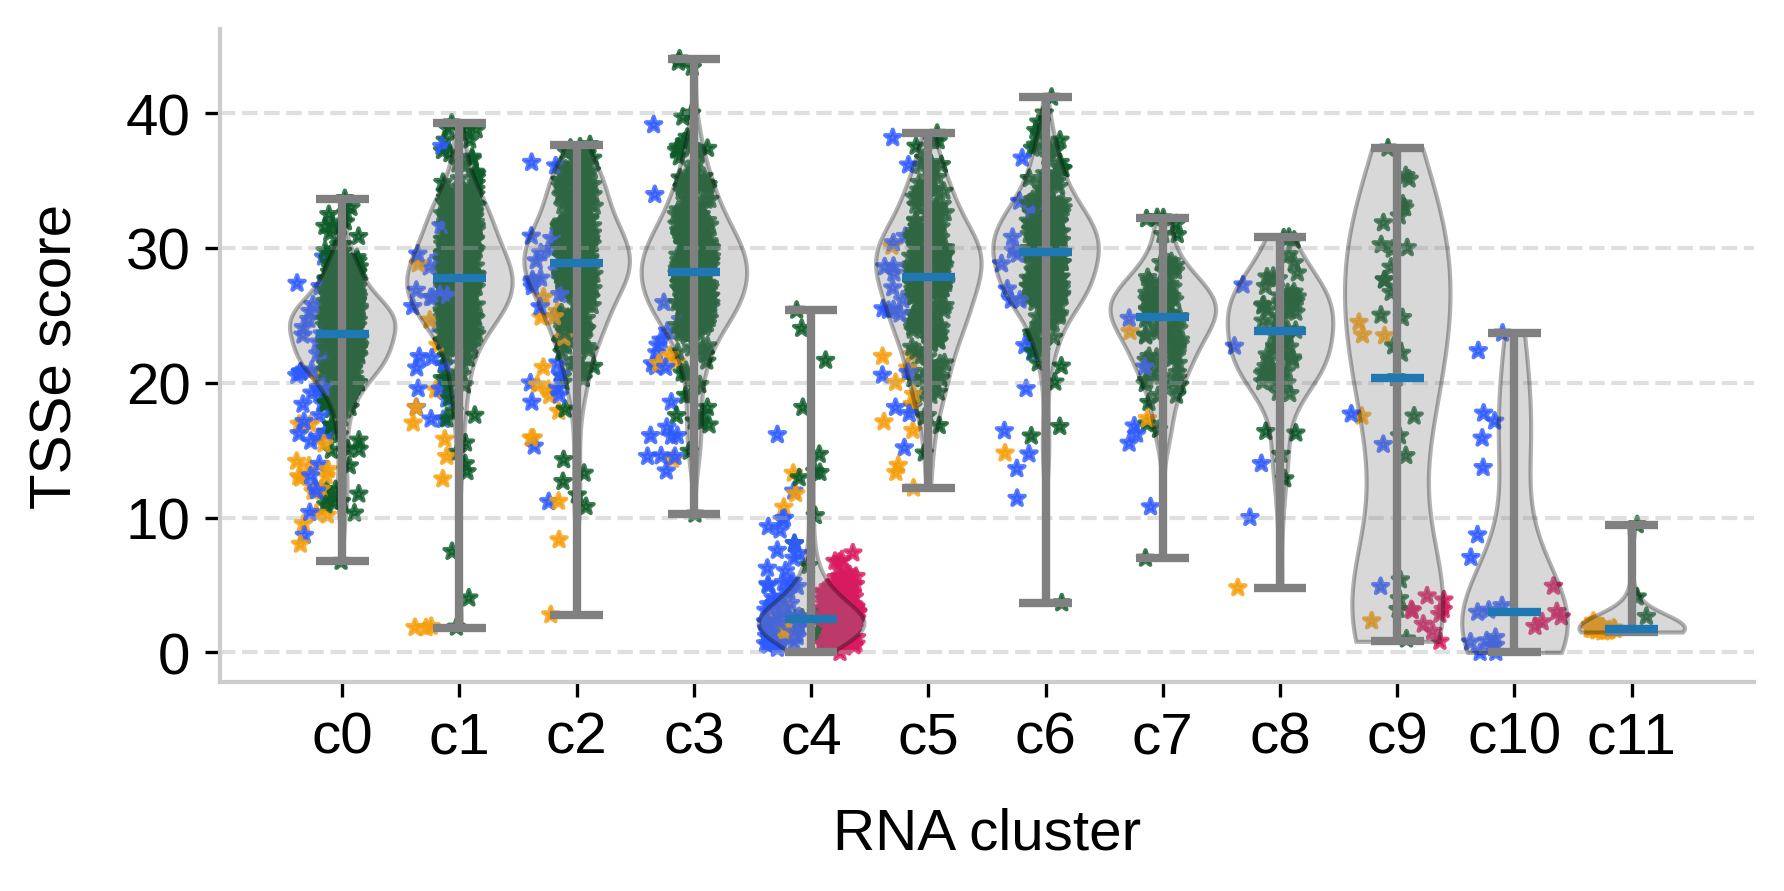

In [37]:
fig= plt.figure(figsize=(6.6, 5))
gs = gridspec.GridSpec(2, 1, height_ratios=[1.3, 1], hspace=0)
ax = fig.add_subplot(gs[0])

RNA_cluster_list = ['0', '1', '2', '3', '4', '5', '6', '7', '8', '9', '10', '11', 'no_rna_info']
RNA_cluster_list = ['0', '1', '2', '3', '4', '5', '6', '7', '8', '9', '10', '11']
tsse_score_list = [
    data.obs[data.obs['leiden_RNA_scVI'] == cluster]['tsse'] for cluster in RNA_cluster_list
]
tsse_color_list = [
    data.obs.loc[data.obs['leiden_RNA_scVI'] == cluster, '_2set_identified_by_atac_SC_mod'].map(SADEvsCR_colors_map) for cluster in RNA_cluster_list
]

jitter_position_offset = [
    data.obs.loc[data.obs['leiden_RNA_scVI'] == cluster, '_2set_identified_by_atac_SC_mod'].map(SADEvsCR_cat_position_map) for cluster in RNA_cluster_list
]

x_positions = np.arange(len(RNA_cluster_list))
v1 = ax.violinplot(tsse_score_list, positions=x_positions, widths=0.9, showmeans=False, showmedians=True)

for met in ['cbars', 'cmins', 'cmaxes']:
    v1[met].set_color('grey')
for i, body in enumerate(v1['bodies']):
    body.set_facecolor('grey')
    body.set_edgecolor('black')
    body.set_alpha(0.3)
    body.set_zorder(2)

for i, group_data in enumerate(tsse_score_list):
    add_jittered_points(ax, group_data,x_positions[i] + jitter_position_offset[i], color=tsse_color_list[i], alpha=0.8, s=15, marker='*', 
                        edgecolors=tsse_color_list[i],
                        jitter_width=0.15)


ax.yaxis.grid(True, linestyle='--', alpha=0.4, zorder=0)
ax.set_xticks(x_positions)
ax.set_xticklabels(['c' + cluster for cluster in RNA_cluster_list], fontweight='medium', rotation=0, ha='center')
ax.set_ylabel('TSSe score',  labelpad=10)
ax.set_xlabel('RNA cluster', labelpad=10)


for spine in ['top', 'right']:
    ax.spines[spine].set_visible(False)
for spine in ['left', 'bottom']:
    ax.spines[spine].set_color('#cccccc')

fig.savefig(os.path.join(os.getcwd(), '_figures', 'fig4_p4.png'), bbox_inches='tight', dpi=300)
fig.savefig(os.path.join(os.getcwd(), '_figures', 'fig4_p4.pdf'), bbox_inches='tight')

# Gene activity score

In [43]:
gene_matrix = snap.pp.make_gene_matrix(data, snap.genome.hg38)
gene_matrix.obsm["X_umap"] = data.obsm["X_umap"]
gene_matrix

AnnData object with n_obs × n_vars = 2384 × 60606
    obs: 'n_fragment', 'frac_dup', 'frac_mito', 'rna_pass_CR', 'atac_pass_CR', 'atac_pass_entropy', 'atac_pass_archr_TSS', '_2set_identified_by_atac_SC', '_2set_identified_by_atac_ST', '_3set_identified_by_atac', 'DNA_debris', 'amulet_doublet_atac', 'tsse', 'leiden', 'leiden_RNA_scVI', 'filtered_leiden', 'debris_doublets_flag', '_2set_identified_by_atac_SC_mod'
    obsm: 'X_umap'

In [44]:
sc.pp.filter_genes(gene_matrix, min_cells= 5)
sc.pp.normalize_total(gene_matrix)
sc.pp.log1p(gene_matrix)
gene_matrix

AnnData object with n_obs × n_vars = 2384 × 58486
    obs: 'n_fragment', 'frac_dup', 'frac_mito', 'rna_pass_CR', 'atac_pass_CR', 'atac_pass_entropy', 'atac_pass_archr_TSS', '_2set_identified_by_atac_SC', '_2set_identified_by_atac_ST', '_3set_identified_by_atac', 'DNA_debris', 'amulet_doublet_atac', 'tsse', 'leiden', 'leiden_RNA_scVI', 'filtered_leiden', 'debris_doublets_flag', '_2set_identified_by_atac_SC_mod'
    var: 'n_cells'
    uns: 'log1p'
    obsm: 'X_umap'

## Vis in heatmap

In [57]:
debris_or_doublet_cat= [ 'doublets', 'debrisNdoublet', 'Debris', 'Debris_or_doublet']
debris_or_doublet_map = dict(zip(debris_or_doublet_cat, [  "#a50026", '#a50026', "#a50026",  "#a50026"]))


pass_cr_map = {False: "#a50026"} # True: (0,0,0,0), }
dna_debris_map = {'YES': "#a50026"}#, 'NO': '#FFFFFF'}

amulet_doublet_colors_map = {True: '#a50026'} # False: "#FFFFFF", }

filtered_leiden_colors_map = dict(zip( scanpy_cluster + ['Debris_or_doublet'], scanpy_colors + ['black'],))

In [48]:
gene_matrix.obs['amulet_doublet_atac'].value_counts()

amulet_doublet_atac
False    2288
True       96
Name: count, dtype: int64

In [ ]:
quiescent_regulation_genes = ['TP53',    'IKZF1',  'SATB1', 'YY1', 'TFEB', 'RBPJ'] #, 'HES1', ]

Tcells= ['IL7R',] #'CD3G', 'CD3E', 'CD3D',  ] 
B_cell = ['MS4A1', 'CD79A']# , 'CD19', ]
NK = [ 'FCGR3A', 'NCAM1'] # NKG7',FCGR3A', 'NCAM1'
mono = [ 'CD14',   'CD68',   ]# ,  CD14, FCGR1A, CD68
naiveTcells = [ "CCR7",	  ]#  "CCR7",	 'IL7R',
DC=[  'CD1C',  ] # 'SERPINF1',  
cytotoxic_T = ['CD8A', 'CD8B',]
#mono_or_DC = ['HLA-DRA'] # for umap 
#naiveThelper = [   'CD4', ] # for umap 

housekeeping_genes = ['GNB1', 'PRPF38B',  'CDC42SE1', 'PPP2R5A',] # 'CMPK1', 'COX7A2L', 'SF3B1', 'CTDSP1']

marker_genes_redor =Tcells  + naiveTcells +  cytotoxic_T+  NK+ mono + DC + B_cell    + housekeeping_genes 
marker_genes_redor_delux = marker_genes_redor + quiescent_regulation_genes

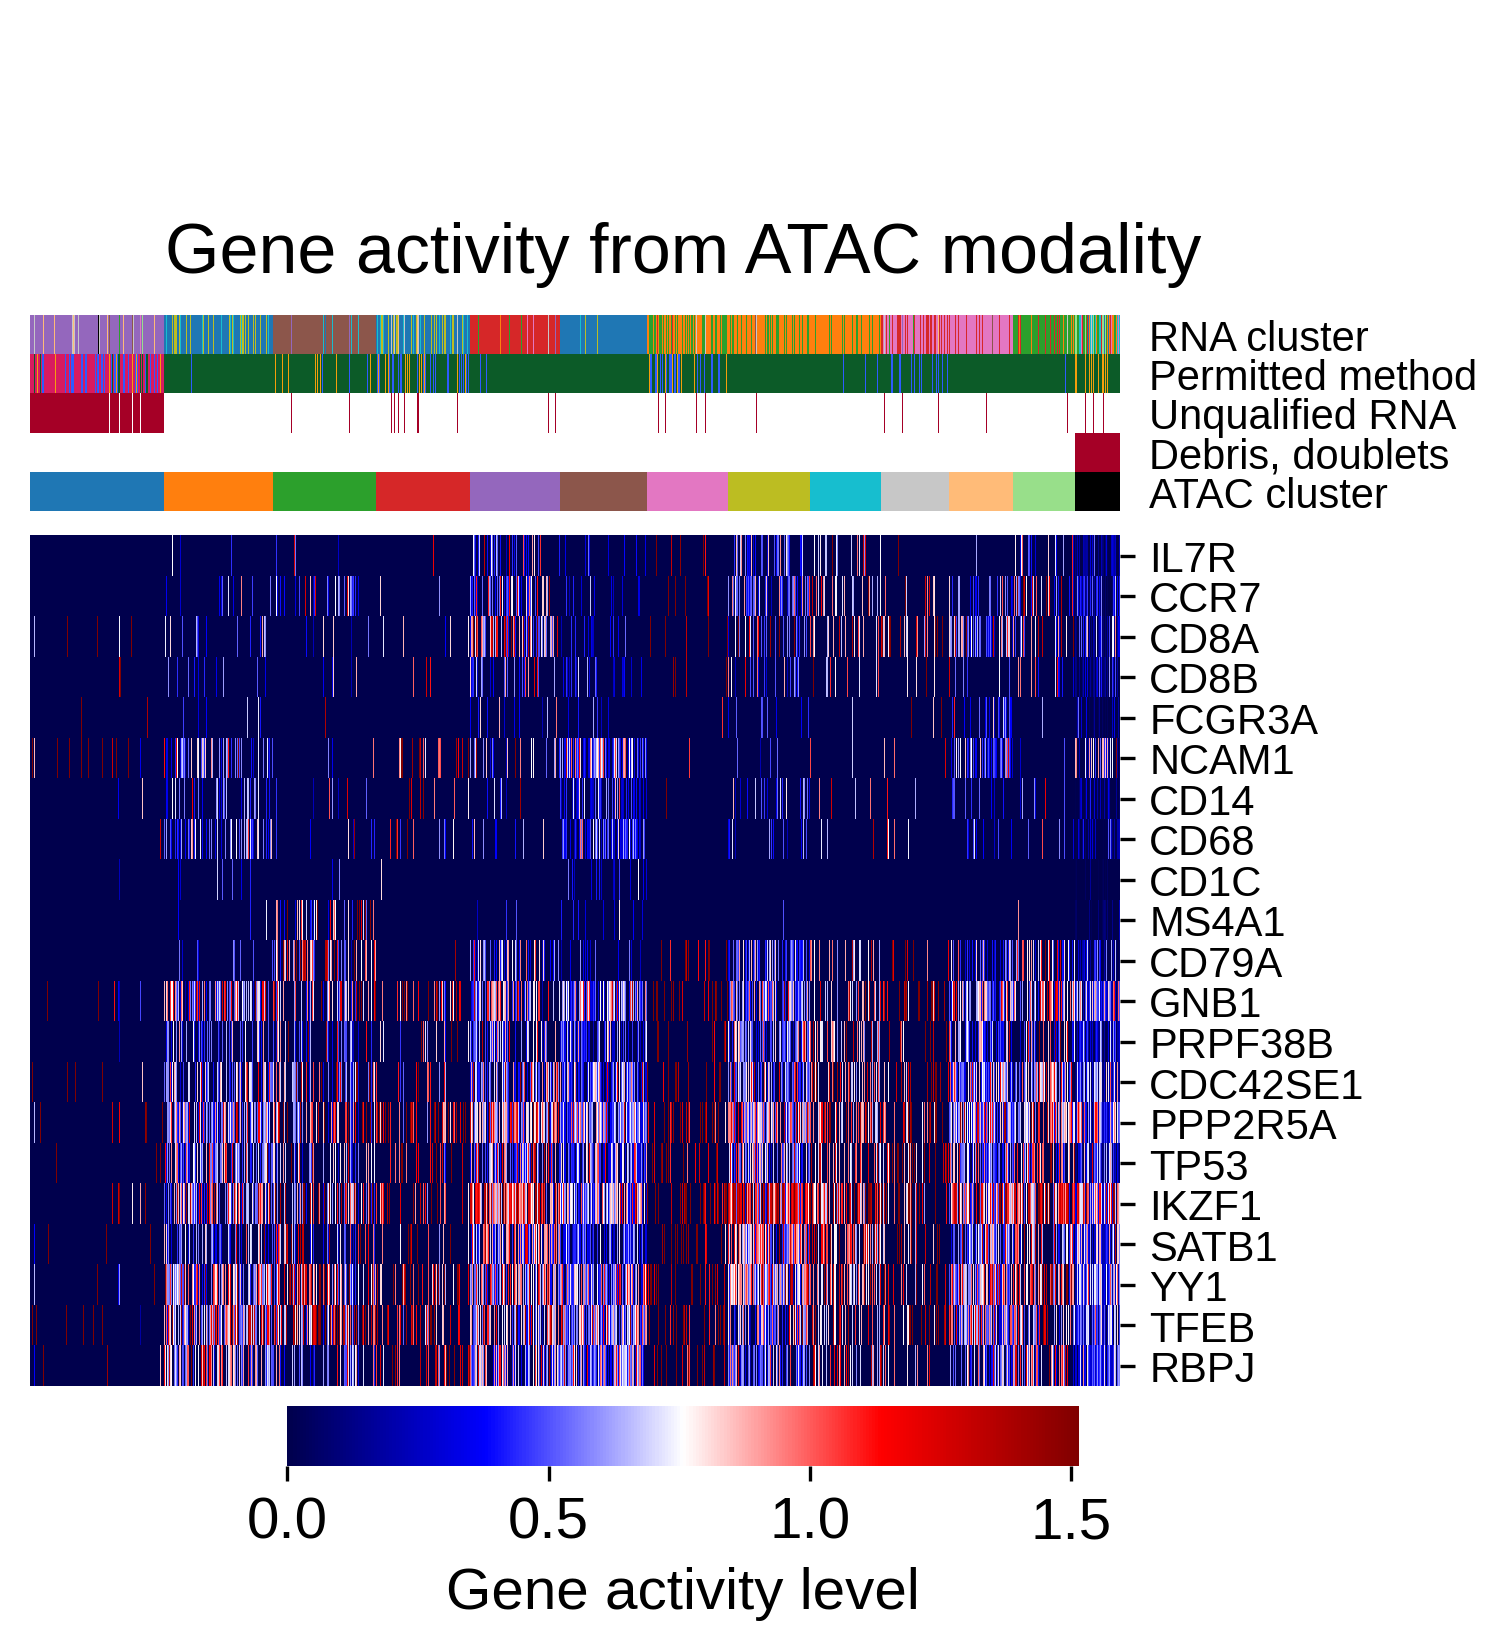

In [59]:
# heatmap          
mat = gene_matrix[:, marker_genes_redor_delux].X.toarray()
df = pd.DataFrame(mat, index=gene_matrix.obs.index, columns= marker_genes_redor_delux).T

vmean = df.values.mean()
vsd = df.values.std()
vmin= 0.
vmax = np.min((df.values.max(), vmean + 3*vsd))
vcenter = vmax/2

#Create metadata for the columns
metadata = gene_matrix.obs[['leiden_RNA_scVI', '_3set_identified_by_atac', '_2set_identified_by_atac_SC_mod', 'DNA_debris', 'rna_pass_CR', 'leiden', 'filtered_leiden', 'amulet_doublet_atac', 'debris_doublets_flag']].copy()
cell_index = gene_matrix.obs['filtered_leiden'].astype('category').sort_values().index


col_colors = pd.DataFrame({
    'RNA cluster': metadata['leiden_RNA_scVI'].map(scanpy_color_map).fillna('black'),
    'Permitted method': metadata['_2set_identified_by_atac_SC_mod'].map(SADEvsCR_colors_map),
    'Unqualified RNA': metadata['rna_pass_CR'].map(pass_cr_map),
    'Debris, doublets': metadata['debris_doublets_flag'].map(debris_or_doublet_map),
    'ATAC cluster': metadata['filtered_leiden'].map(lambda x: str(x).split('.')[0]).astype('category').map(filtered_leiden_colors_map),
    # 'DNA-debris': metadata['DNA_debris'].map(dna_debris_map),
    # 'Amulet doublet': metadata['amulet_doublet_atac'].map(amulet_doublet_colors_map),
    #'atac_leiden': metadata['leiden'].map(scanpy_color_map),
}, index=metadata.index)

# 4. Plot the clustermap
g = sns.clustermap(df.loc[:, cell_index], col_colors=col_colors.loc[cell_index], cmap='seismic', #cmap='seismic', 
                   figsize=(6.6, 5), col_cluster=False, xticklabels=False, row_cluster=False, yticklabels=True,
                   cbar_pos=(0.3, 0., 0.4, 0.04), 
                   cbar_kws={"orientation": "horizontal", 'label': 'Gene activity level'},
                  vmin=vmin, vmax=vmax,  center= vcenter
                  )
g.tick_params(axis='y', labelsize=10)
# g.ax_heatmap.tick_params(axis='y', labelsize=10)
g.ax_row_dendrogram.set_visible(False) # Hide Row tree
g.ax_col_colors.tick_params(axis='y', labelsize=10,    labelright=True, right=False)


g.fig.suptitle('Gene activity from ATAC modality',
               y=0.83) #
g.savefig(os.path.join(os.getcwd(), '_figures', 'fig5_p1.png'), dpi=600, bbox_inches='tight')
g.savefig(os.path.join(os.getcwd(), '_figures', 'fig5_p1.pdf'),  bbox_inches='tight')

## Reorder cells to have consistency with RNA heatmap

In [60]:
rna_cell_index_file = os.path.join(Union_cell_subdir, '_unioncell_rna_order_index.csv')
rna_cell_index = pd.read_csv(rna_cell_index_file, index_col=0, header=0)
rna_cell_index['atac_bc'] = rna_cell_index['atac_barcodes'] + '-1'
rna_cell_index = rna_cell_index.set_index('atac_bc')
print(rna_cell_index.shape)
rna_cell_index.head(2)

(2381, 2)


,rna_barcodes,atac_barcodes
atac_bc,,
GTTTGGTGTGCAGTAA-1,TTTGTGGCAGTATGTT,GTTTGGTGTGCAGTAA
GGTCATGAGCTAAATG-1,GCTAGTGTCCCGTTAC,GGTCATGAGCTAAATG


In [61]:
# 3 cells do not have RNA data and only ATAC, do need to add to the index for heat map plot's consistency
for cell in gene_matrix.obs.index:
    if cell not in rna_cell_index['atac_barcodes']:
        rna_cell_index.loc[cell, 'rna_barcodes'] =None

In [62]:
rna_cell_index['rna_barcodes'].isna().sum()

np.int64(3)

In [63]:
rna_cell_index.tail(5)

,rna_barcodes,atac_barcodes
atac_bc,,
TGCGCCTCATCCTGCA-1,AAGTGTTGTTTCCTCC,TGCGCCTCATCCTGCA
TCCTCCATCAGGTTCC-1,TGAAGTGAGGATTGAG,TCCTCCATCAGGTTCC
CGAATAATCTCACTTC-1,None,NaN
CGGTTTATCCTAAATC-1,None,NaN
GTTAGGAGTGCTCATG-1,None,NaN


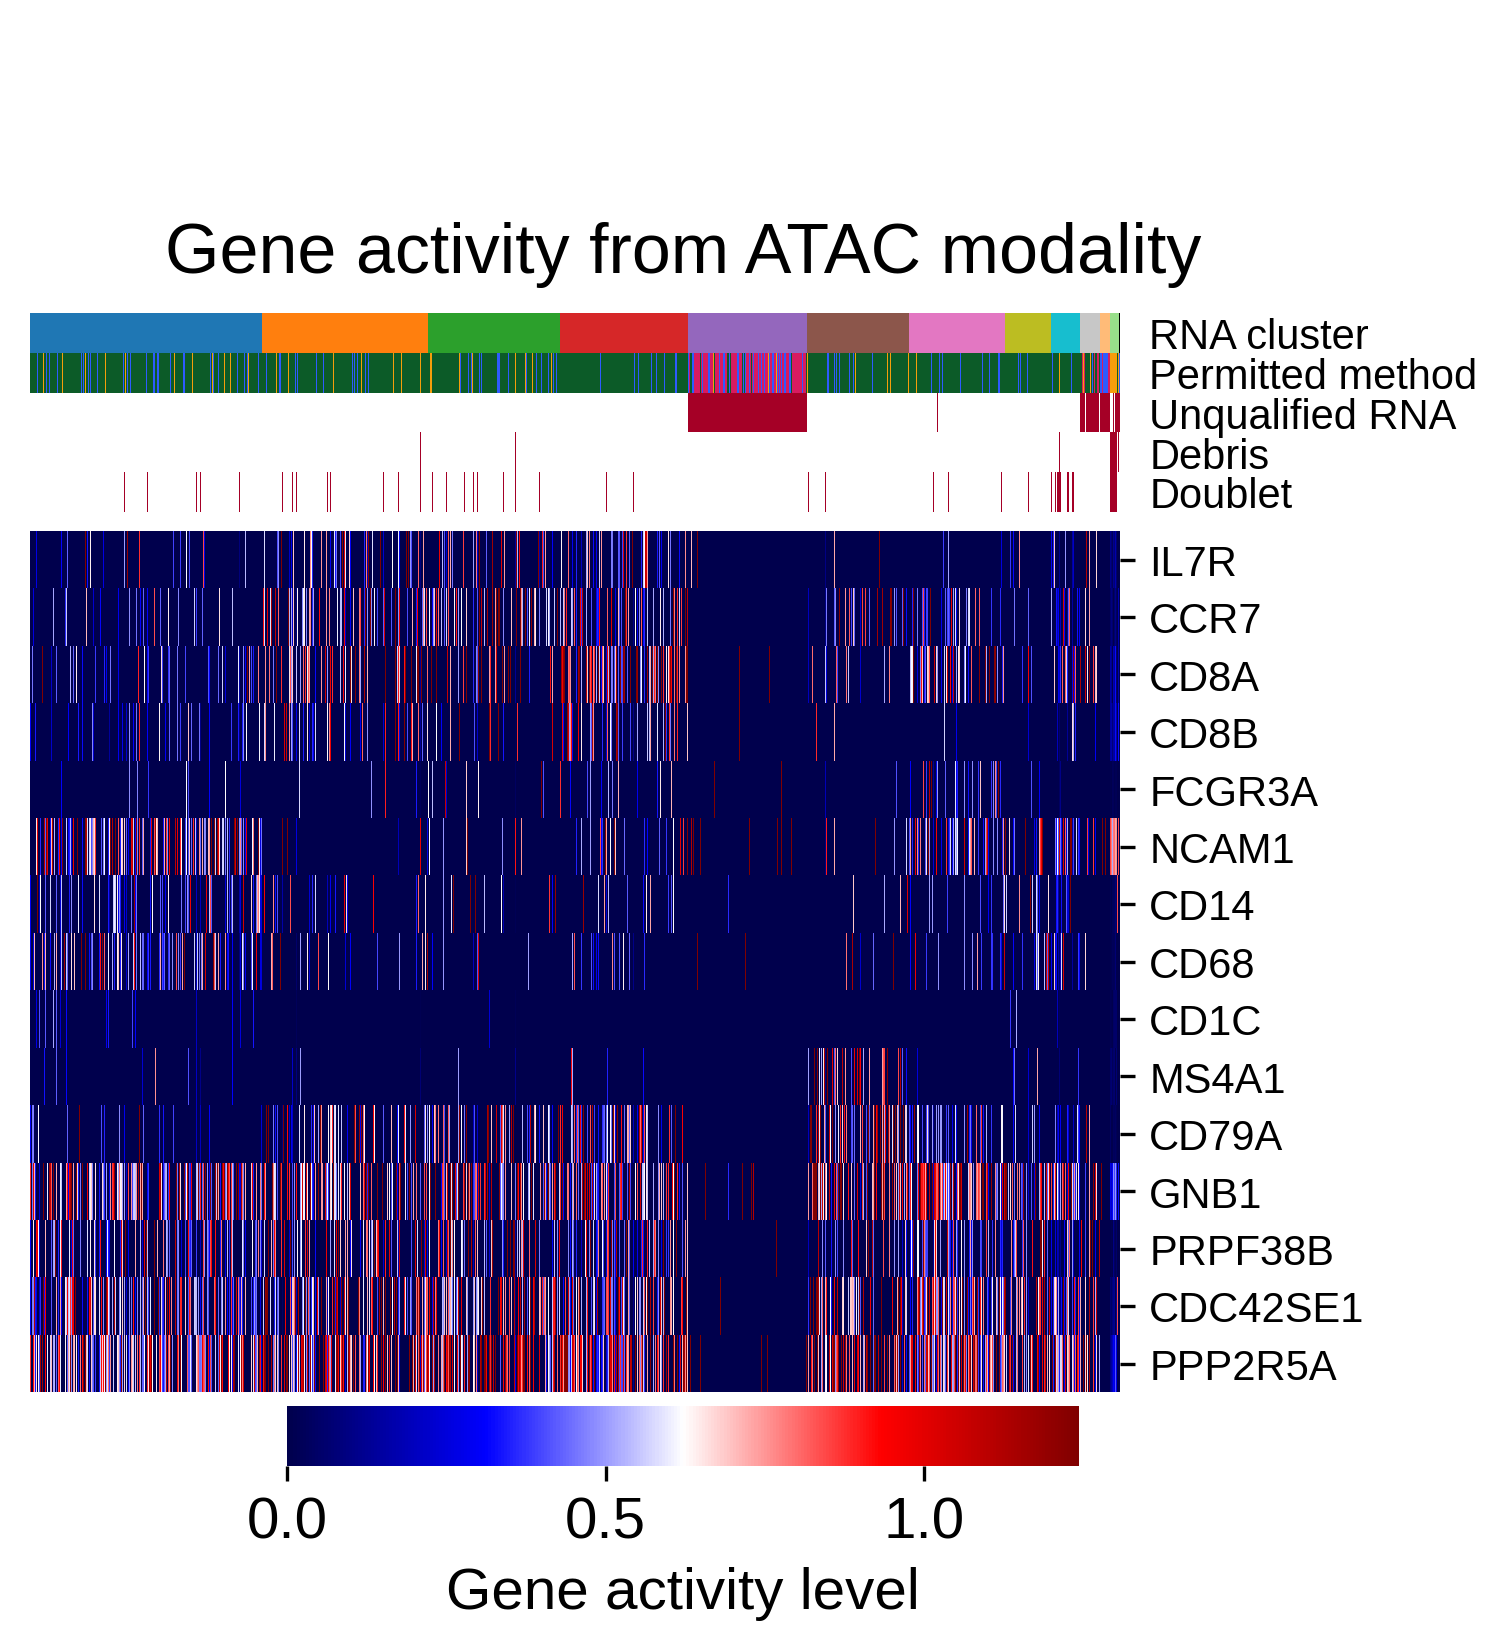

In [65]:
np.random.seed(42)  # For reproducibility of jitter
mat = gene_matrix[:, marker_genes_redor].X.toarray()
df = pd.DataFrame(mat, index=gene_matrix.obs.index, columns= marker_genes_redor).T

vmean = df.values.mean()
vsd = df.values.std()
vmin= 0.
vmax = np.min((df.values.max(), vmean + 3*vsd))
vcenter = vmax/2

#Create metadata for the columns
metadata = gene_matrix.obs[['leiden_RNA_scVI', '_2set_identified_by_atac_SC_mod', 'debris_doublets_flag', 'rna_pass_CR', 'leiden', 'filtered_leiden', 'DNA_debris', 'amulet_doublet_atac']].copy()


col_colors = pd.DataFrame({
    'RNA cluster': metadata['leiden_RNA_scVI'].map(scanpy_color_map).fillna('black'),
    'Permitted method': metadata['_2set_identified_by_atac_SC_mod'].map(SADEvsCR_colors_map),
    'Unqualified RNA': metadata['rna_pass_CR'].map(pass_cr_map),
    'Debris': metadata['DNA_debris'].map(dna_debris_map),
    'Doublet': metadata['amulet_doublet_atac'].map(amulet_doublet_colors_map),
    #'Debris, doublets': metadata['debris_doublets_flag'].map(debris_or_doublet_map)
}, index=metadata.index)

num_color_rows = col_colors.shape[1]
dynamic_ratio = 0.018 * num_color_rows

cell_index = rna_cell_index.index
cell_index.name = None

# 4. Plot the clustermap
g = sns.clustermap(df.loc[:,cell_index], col_colors=col_colors.loc[cell_index], cmap='seismic',  linewidths=0, 
                   figsize=(6.6, 5), col_cluster=False, xticklabels=False, row_cluster=False, yticklabels=True,
                   cbar_pos=(0.3, 0., 0.4, 0.04), # Horizontal bar at bottom center
                   cbar_kws={"orientation": "horizontal", 'label': 'Gene activity level'}, #colors_ratio=dynamic_ratio,
                   vmin=vmin, vmax=vmax,  center= vcenter
                  )

g.tick_params(axis='y', labelsize=10)
g.ax_heatmap.tick_params(axis='y', labelsize=10)
g.ax_row_dendrogram.set_visible(False) # Hide Row tree
g.ax_col_colors.tick_params(axis='y', labelsize=10,    labelright=True, right=False)


g.fig.suptitle('Gene activity from ATAC modality',
               y=0.83) #
g.savefig(os.path.join(os.getcwd(), '_figures', 'fig4_p5.png'), dpi=600, bbox_inches='tight')
g.savefig(os.path.join(os.getcwd(), '_figures', 'fig4_p5.pdf'),  bbox_inches='tight')

In [66]:
gene_matrix.obs.groupby(['rna_pass_CR', 'leiden_RNA_scVI']).size().unstack(fill_value=0)

leiden_RNA_scVI,0,1,10,11,2,3,4,5,6,7,8,9,no_rna_info
rna_pass_CR,,,,,,,,,,,,,
False,1,2,23,10,0,2,261,0,1,0,0,37,3
True,507,361,0,9,289,276,0,224,208,101,63,6,0


## Umap for each marker 

In [68]:
mono = ['CD14',   'HLA-DRA',  'LYZ', 'TNF', 'IL1B']
NK = [  'CD3D', 'KLRG1',   'NCR3','KLRB1', 'NKG7']
gamma_delta_T = ['TRDC',   'TRGC1','TRDV2', 'TRGV9']
B_cell = ['MS4A1']
housekeeping_genes = ['GNB1','CMPK1', 'PRPF38B',  'CDC42SE1', 'PPP2R5A', 'COX7A2L', 'SF3B1', 'CTDSP1']
marker_genes = ['LEF1',  'TREM1',  'PPBP'] + B_cell +  mono + NK + gamma_delta_T + housekeeping_genes

quiescent_regulation_genes = ['TP53',  ]
fig = sc.pl.umap(gene_matrix, color=['leiden', 'leiden_RNA_scVI'] + marker_genes + quiescent_regulation_genes, s=20, ncols=4, wspace=0.4,
           return_fig=True)
fig.suptitle('ATAC modality gene activity', y=0.9)

Text(0.5, 0.9, 'ATAC modality gene activity')

## Save results

In [72]:
# Save gene-activity results 
gene_matrix.obs['filtered_leiden'] = gene_matrix.obs['filtered_leiden'].astype('str')
gene_matrix.write_h5ad(os.path.join(Union_cell_subdir, '_SNAPataC_analysis', 'union_cell_snapatac_gene_activity.h5ad'))

# Save average gene activity for each cluster
cluster_average_df = pd.DataFrame(index=gene_matrix.var_names)

for c in gene_matrix.obs['filtered_leiden'].unique():
    a = gene_matrix[gene_matrix.obs['filtered_leiden'] == c, :].X.mean(axis=0)
    cluster_average_df[c] = np.asarray(a).flatten()

gene_activity_file = os.path.join(Union_cell_subdir, '_SNAPataC_analysis', 'filtered_leiden_cluster_average_gene_activity.csv')
cluster_average_df.to_csv(gene_activity_file)

cluster_average_df.head()

... storing 'filtered_leiden' as categorical


,9.0,0.0,2.0,3.0,5.0,Debris_or_doublet,4.0,11.0,1.0,8.0,6.0,7.0,10.0
DDX11L1,0.010036,0.000000,0.0,0.006501,0.002530,0.001486,0.001451,0.004668,0.013779,0.0,0.004018,0.009837,0.014753
WASH7P,0.000000,0.000000,0.0,0.000000,0.000000,0.000596,0.000000,0.000000,0.002664,0.0,0.000000,0.000000,0.000000
OR4F5,0.000000,0.002411,0.0,0.000000,0.001871,0.000657,0.000000,0.000000,0.000000,0.0,0.000000,0.000000,0.000000
ENSG00000238009,0.004985,0.000000,0.0,0.000000,0.009980,0.001632,0.002370,0.000000,0.001786,0.0,0.000000,0.002715,0.000000
ENSG00000268903,0.000000,0.000000,0.0,0.000000,0.000000,0.002213,0.002370,0.000000,0.000000,0.0,0.000000,0.000000,0.000000
